In [1]:
import matplotlib.pyplot as plt
import numpy as np
from Bio import Align
from Bio.SeqUtils import seq1
from prody import *

# Parse C-alphas
g1_ca = parsePDB("8wflout.pdb").select("protein and calpha")
g2_ca = parsePDB("9hueout.pdb").select("protein and calpha")
g1_model_ca = parsePDB("remodelled_glyt1_bestout.pdb").select(
    "protein and calpha"
)

# Extract FASTA sequences
seq_g1 = "".join([seq1(res) for res in g1_ca.getResnames()])
seq_g2 = "".join([seq1(res) for res in g2_ca.getResnames()])
seq_g1_model = "".join([seq1(res) for res in g1_model_ca.getResnames()])

# Global pairwise alignment (GlyT1 vs. GlyT2)
aligner = Align.PairwiseAligner()
aligner.mode = "global"
aligner.substitution_matrix = Align.substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5

# Align
aln = aligner.align(seq_g1, seq_g2)[0]
aligned_g1, aligned_g2 = aln[0], aln[1]

# Filter strictly matching aligned pairs
g1_indices = []
g2_indices = []
idx_g1 = 0
idx_g2 = 0

for a, b in zip(aligned_g1, aligned_g2):
  if a != "-" and b != "-":
    g1_indices.append(idx_g1)
    g2_indices.append(idx_g2)
  if a != "-":
    idx_g1 += 1
  if b != "-":
    idx_g2 += 1

# Check if model sequence length matches 8wfl exactly
if seq_g1 == seq_g1_model:
  g1_model_indices = g1_indices
else:
  # In case the homology model has terminal truncations, align model to g1
  aln_mod = aligner.align(seq_g1, seq_g1_model)[0]
  # Map indices via g1 reference
  g1_to_mod = {}
  i_g1, i_mod = 0, 0
  for a, m in zip(aln_mod[0], aln_mod[1]):
    if a != "-" and m != "-":
      g1_to_mod[i_g1] = i_mod
    if a != "-":
      i_g1 += 1
    if m != "-":
      i_mod += 1

  # Retain only indices present in all three
  valid_triplets = [i for i in g1_indices if i in g1_to_mod]
  g2_indices = [
      g2_indices[k] for k, i in enumerate(g1_indices) if i in g1_to_mod
  ]
  g1_model_indices = [g1_to_mod[i] for i in valid_triplets]
  g1_indices = valid_triplets

# Extract aligned Subsets
matched_g1 = g1_ca[g1_indices]
matched_g2 = g2_ca[g2_indices]
matched_g1_model = g1_model_ca[g1_model_indices]

print(f"Matched {len(matched_g1)} homologous C-alpha triplets.")

@> 4414 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 4697 atoms and 1 coordinate set(s) were parsed in 0.02s.
@> 5145 atoms and 1 coordinate set(s) were parsed in 0.02s.


Matched 550 homologous C-alpha triplets.


@> Hessian was built in 0.03s.
@> 1644 modes were calculated in 1.01s.
@> Hessian was built in 0.04s.
@> WARNING More than 6 (12) zero eigenvalues were calculated.
@> Solving for additional eigenvalues...
@> 1638 modes were calculated in 0.74s.
@> Hessian was built in 0.04s.
@> WARNING More than 6 (7) zero eigenvalues were calculated.
@> Solving for additional eigenvalues...
@> 1643 modes were calculated in 0.75s.
@> Hessian was built in 0.05s.
@> 1644 modes were calculated in 0.70s.
@> Hessian was built in 0.06s.
@> 1644 modes were calculated in 0.55s.
@> Hessian was built in 0.06s.
@> 1644 modes were calculated in 0.77s.
@> Hessian was built in 0.07s.
@> 1644 modes were calculated in 0.69s.
@> Hessian was built in 0.07s.
@> 1644 modes were calculated in 0.55s.
@> Hessian was built in 0.08s.
@> 1644 modes were calculated in 0.57s.
@> Hessian was built in 0.10s.
@> 1644 modes were calculated in 0.54s.
@> Hessian was built in 0.10s.
@> 1644 modes were calculated in 0.54s.
@> Hessian was

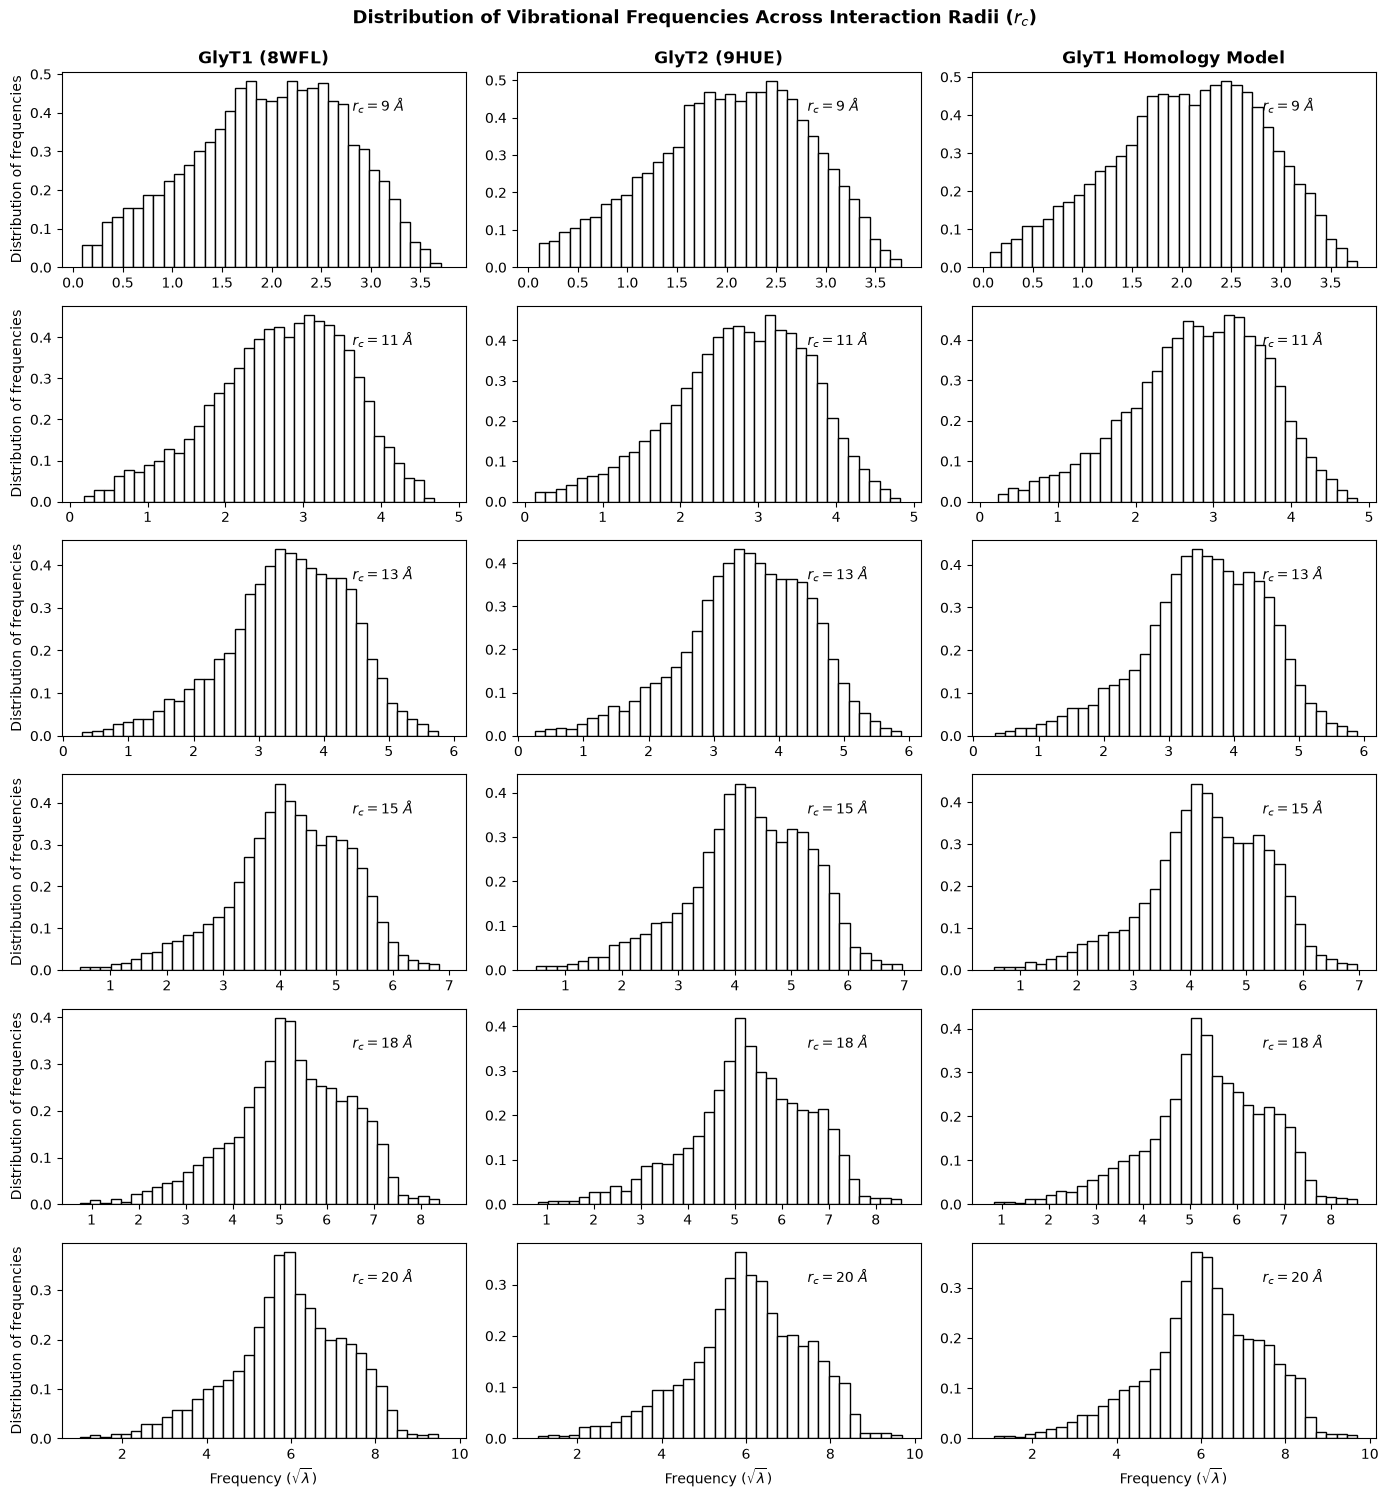

In [ ]:
from prody import *

# Radii to test
radii = [9.0, 11.0, 13.0, 15.0, 18.0, 20.0]

# 3 columns: GlyT1 (8WFL), GlyT2 (9HUE), GlyT1 Model
fig, axes = plt.subplots(
    len(radii), 3, figsize=(14, 2.5 * len(radii)), sharex="row"
)

for row_idx, rc in enumerate(radii):
  # 1. GlyT1 (8WFL)
  anm1 = ANM(f"GlyT1_rc{rc}")
  anm1.buildHessian(matched_g1, cutoff=rc)
  anm1.calcModes(n_modes=None)
  freqs_g1 = np.sqrt(anm1.getEigvals())

  # 2. GlyT2 (9HUE)
  anm2 = ANM(f"GlyT2_rc{rc}")
  anm2.buildHessian(matched_g2, cutoff=rc)
  anm2.calcModes(n_modes=None)
  freqs_g2 = np.sqrt(anm2.getEigvals())

  # 3. GlyT1 Homology Model
  anm_mod = ANM(f"GlyT1_Model_rc{rc}")
  anm_mod.buildHessian(matched_g1_model, cutoff=rc)
  anm_mod.calcModes(n_modes=None)
  freqs_mod = np.sqrt(anm_mod.getEigvals())

  rc_label = f"$r_c = {int(rc) if rc.is_integer() else rc}\\ \\AA$"

  ax_g1 = axes[row_idx, 0]
  ax_g1.hist(
      freqs_g1,
      bins=35,
      density=True,
      histtype="bar",
      edgecolor="black",
      linewidth=1.0,
      color="white",
  )
  ax_g1.text(
      0.72,
      0.80,
      rc_label,
      transform=ax_g1.transAxes,
      fontsize=10,
      fontweight="bold",
  )
  if row_idx == 0:
    ax_g1.set_title("GlyT1 (8WFL)", fontsize=12, fontweight="bold")
  if row_idx == len(radii) - 1:
    ax_g1.set_xlabel("Frequency ($\sqrt{\lambda}$)", fontsize=10)
  ax_g1.set_ylabel("Distribution of frequencies", fontsize=10)

  ax_g2 = axes[row_idx, 1]
  ax_g2.hist(
      freqs_g2,
      bins=35,
      density=True,
      histtype="bar",
      edgecolor="black",
      linewidth=1.0,
      color="white",
  )
  ax_g2.text(
      0.72,
      0.80,
      rc_label,
      transform=ax_g2.transAxes,
      fontsize=10,
      fontweight="bold",
  )
  if row_idx == 0:
    ax_g2.set_title("GlyT2 (9HUE)", fontsize=12, fontweight="bold")
  if row_idx == len(radii) - 1:
    ax_g2.set_xlabel("Frequency ($\sqrt{\lambda}$)", fontsize=10)
    
  ax_mod = axes[row_idx, 2]
  ax_mod.hist(
      freqs_mod,
      bins=35,
      density=True,
      histtype="bar",
      edgecolor="black",
      linewidth=1.0,
      color="white",
  )
  ax_mod.text(
      0.72,
      0.80,
      rc_label,
      transform=ax_mod.transAxes,
      fontsize=10,
      fontweight="bold",
  )
  if row_idx == 0:
    ax_mod.set_title("GlyT1 Homology Model", fontsize=12, fontweight="bold")
  if row_idx == len(radii) - 1:
    ax_mod.set_xlabel("Frequency ($\sqrt{\lambda}$)", fontsize=10)

plt.suptitle(
    "Distribution of Vibrational Frequencies Across Interaction Radii ($r_c$)",
    fontsize=13,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout()
plt.show()

In [3]:
# Build identical Elastic Network Models
cutoff = 13.0
n_modes = 15  # Slowest collective breathing modes

anm1 = ANM("GlyT1")
anm1.buildHessian(matched_g1, cutoff=cutoff)
anm1.calcModes(n_modes=n_modes)
dccm1 = calcCrossCorr(anm1)

anm2 = ANM("GlyT2")
anm2.buildHessian(matched_g2, cutoff=cutoff)
anm2.calcModes(n_modes=n_modes)
dccm2 = calcCrossCorr(anm2)

anm_model = ANM("GlyT1_Model")
anm_model.buildHessian(matched_g1_model, cutoff=cutoff)
anm_model.calcModes(n_modes=n_modes)
dccm_model = calcCrossCorr(anm_model)

# Compute Dynamic Difference Matrices
delta_dccm_exp = dccm1 - dccm2  # Experimental divergence
delta_dccm_mod_vs_g2 = dccm_model - dccm2  # Sequence shift on template
delta_dccm_mod_vs_g1 = dccm_model - dccm1  # Conformation shift on sequence

@> Hessian was built in 0.08s.
@> 15 modes were calculated in 0.20s.
@> Hessian was built in 0.07s.
@> 15 modes were calculated in 0.22s.
@> Hessian was built in 0.07s.
@> 15 modes were calculated in 0.23s.


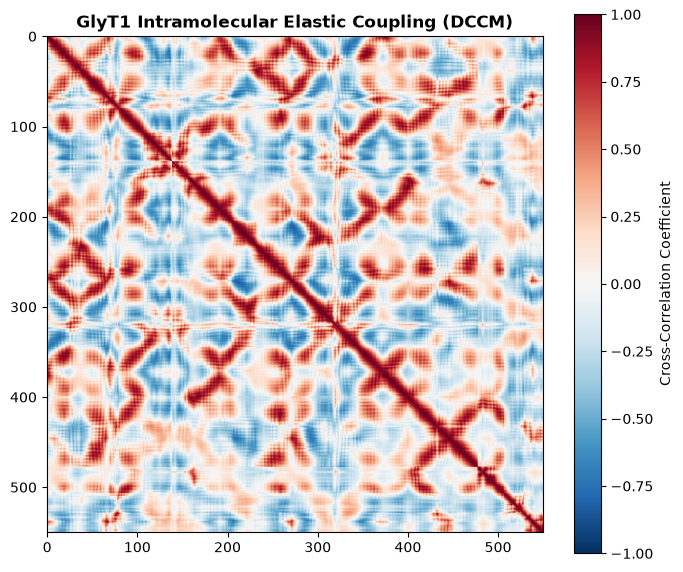

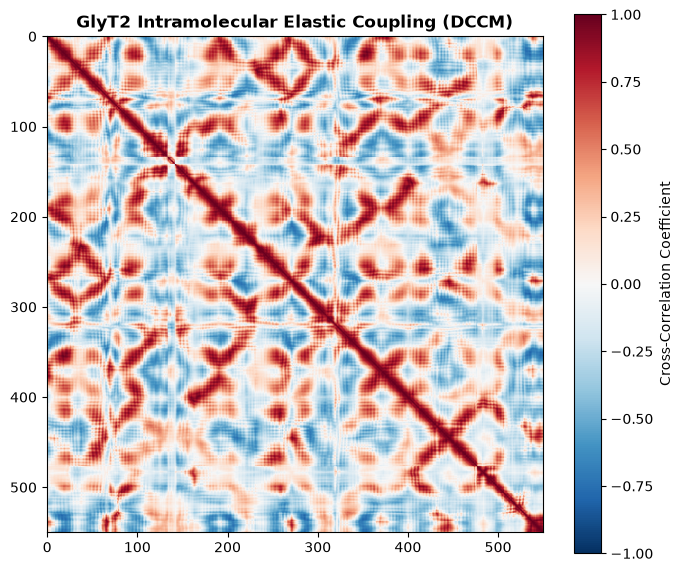

In [4]:
plt.figure(figsize=(8, 7))
plt.imshow(dccm1, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Cross-Correlation Coefficient")
plt.title(
    "GlyT1 Intramolecular Elastic Coupling (DCCM)",
    fontsize=12,
    fontweight="bold",
)
plt.show()

plt.figure(figsize=(8, 7))
plt.imshow(dccm2, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Cross-Correlation Coefficient")
plt.title(
    "GlyT2 Intramolecular Elastic Coupling (DCCM)",
    fontsize=12,
    fontweight="bold",
)
plt.show()

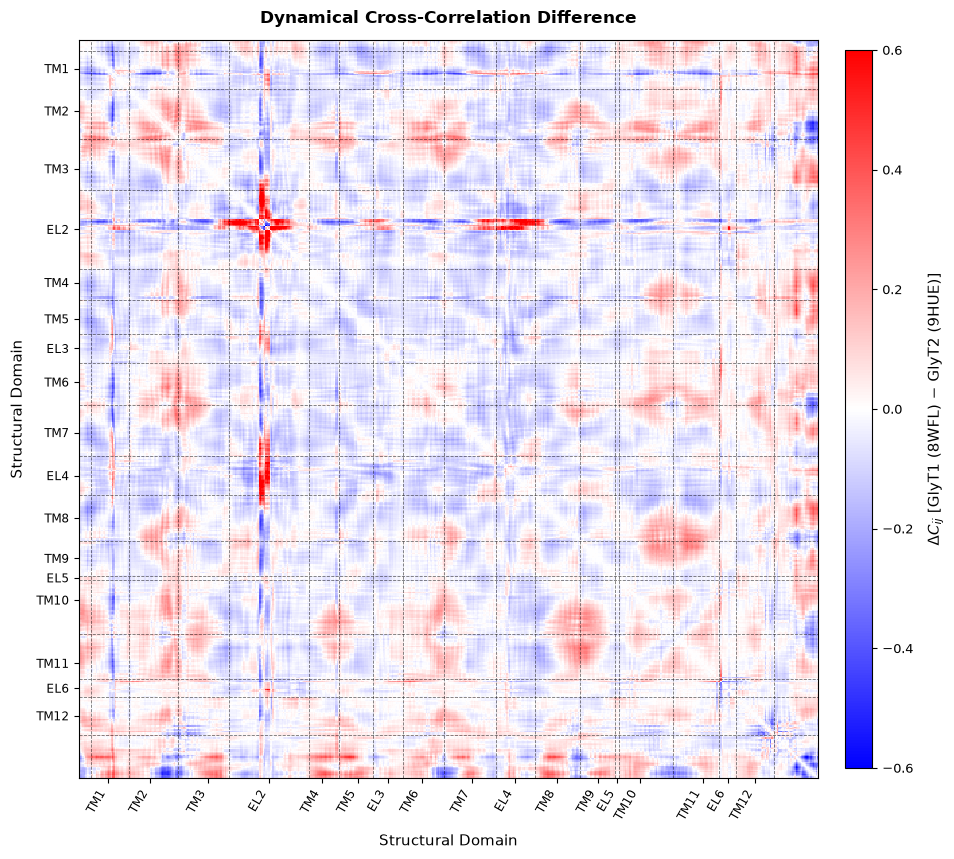

In [5]:
# GlyT1 Transmembrane Helix PDB boundaries 
tm_ranges_g1 = {
    "TM1": (53, 78),
    "TM2": (84, 110),
    "TM3": (125, 155),
    "EL2": (156, 233),
    "TM4": (234, 253),
    "TM5": (260, 281),
    "EL3": (282, 303),
    "TM6": (304, 331),
    "TM7": (338, 372),
    "EL4": (373, 401),
    "TM8": (402, 436),
    "TM9": (437, 462),
    "EL5": (463, 465),
    "TM10": (466, 495),
    "TM11": (516, 539),
    "EL6": (540, 552),
    "TM12": (553, 580),
}

# Convert PDB residue numbers to homologous matrix indices
tm_aligned_bounds = {}
g1_resnums = list(matched_g1.getResnums())

for tm_name, (start_res, end_res) in tm_ranges_g1.items():
  # Find residues within the range present in matched_g1
  indices = [i for i, r in enumerate(g1_resnums) if start_res <= r <= end_res]
  if indices:
    tm_aligned_bounds[tm_name] = (min(indices), max(indices))


# map Structural Domains to Homologous Matrix Indices

g1_resnums = np.array(matched_g1.getResnums())
tm_aligned_bounds = {}
for name, (start_res, end_res) in tm_ranges_g1.items():
  # Extract all homologous indices that fall within the defined residue range
  indices = np.where((g1_resnums >= start_res) & (g1_resnums <= end_res))[0]
  if len(indices) > 0:
    tm_aligned_bounds[name] = (int(indices[0]), int(indices[-1]))

# Preserve the biological sequential order of all domains
ordered_names = [k for k in tm_ranges_g1.keys() if k in tm_aligned_bounds]
single_boundaries = []
tick_locs = []
tick_labels = []

for i in range(len(ordered_names) - 1):
  curr_end = tm_aligned_bounds[ordered_names[i]][1]
  next_start = tm_aligned_bounds[ordered_names[i + 1]][0]
  boundary = (curr_end + next_start) / 2.0
  single_boundaries.append(boundary)


single_boundaries.insert(0, tm_aligned_bounds[ordered_names[0]][0] - 0.5)
single_boundaries.append(tm_aligned_bounds[ordered_names[-1]][1] + 0.5)

for name in ordered_names:
  start_idx, end_idx = tm_aligned_bounds[name]
  tick_locs.append((start_idx + end_idx) / 2.0)
  tick_labels.append(name)

# Plotting
fig, ax = plt.subplots(figsize=(10, 9.5))

vlim = 0.6  
im = ax.imshow(
    delta_dccm_exp,
    cmap="bwr",
    vmin=-vlim,
    vmax=vlim,
    origin="upper",
    interpolation="nearest",
)

cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.03, aspect=26)
cbar.set_label(
    r"$\Delta C_{ij}$ [GlyT1 (8WFL) $-$ GlyT2 (9HUE)]", fontsize=11, labelpad=10
)
cbar.ax.tick_params(labelsize=9)
for b in single_boundaries:
  ax.axvline(
      b, color="black", linestyle="--", linewidth=0.6, alpha=0.55, zorder=3
  )
  ax.axhline(
      b, color="black", linestyle="--", linewidth=0.6, alpha=0.55, zorder=3
  )

ax.set_xticks(tick_locs)
ax.set_xticklabels(tick_labels, rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(tick_locs)
ax.set_yticklabels(tick_labels, fontsize=8.5)

ax.set_xlim(0, len(matched_g1) - 1)
ax.set_ylim(len(matched_g1) - 1, 0)

ax.set_title(
    "Dynamical Cross-Correlation Difference",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Structural Domain", fontsize=11, labelpad=8)
ax.set_ylabel("Structural Domain", fontsize=11, labelpad=8)

plt.tight_layout()
plt.show()

In [7]:
# 6. Sample 40 conformations along Mode 1 (slowest collective breathing mode)
# Setting rmsd=2.0 ensures motions stay within the harmonic limit
mode1_g1_traj = sampleModes(anm1[0], matched_g1, n_confs=40, rmsd=2.0)
mode1_g2_traj = sampleModes(anm2[0], matched_g2, n_confs=40, rmsd=2.0)

# Associate coordinates with the C-alpha atom groups
mode1_g1_traj.setAtoms(matched_g1)
mode1_g2_traj.setAtoms(matched_g2)

# 7. Write multi-model trajectories for visualization
writePDB("glyt1_mode1_traj.pdb", mode1_g1_traj)
writePDB("glyt2_mode1_traj.pdb", mode1_g2_traj)

# 8. Export mode vectors as PDBs with B-factors set to displacement vectors (for porcupine plots)
writePDB("glyt1_mode1_vectors.pdb", matched_g1)
writePDB("glyt2_mode1_vectors.pdb", matched_g2)

print("Trajectories generated: 'glyt1_mode1_traj.pdb' and 'glyt2_mode1_traj.pdb'")

@> Parameter: rmsd = 2.00 A
@> Parameter: n_confs = 40
@> Modes are scaled by 17.966266702277327.
@> Parameter: rmsd = 2.00 A
@> Parameter: n_confs = 40
@> Modes are scaled by 12.117184627054762.


Trajectories generated: 'glyt1_mode1_traj.pdb' and 'glyt2_mode1_traj.pdb'


In [ ]:
# Compute RMSF for all three models (top 15 modes, rc = 13.0 Å)
rmsf_g1 = np.sqrt(calcSqFlucts(anm1))
rmsf_g2 = np.sqrt(calcSqFlucts(anm2))
rmsf_mod = np.sqrt(calcSqFlucts(anm_model))

# Assign RMSF values directly into the B-factor column of each CA subset
matched_g1.setBetas(rmsf_g1)
matched_g2.setBetas(rmsf_g2)
matched_g1_model.setBetas(rmsf_mod)

# Save the annotated PDB files
writePDB("glyt1_anm.pdb", matched_g1)
writePDB("glyt2_anm.pdb", matched_g2)
writePDB("glyt1_model_anm.pdb", matched_g1_model)

# Determine shared robust scale limits across all three structures
all_values = np.concatenate([rmsf_g1, rmsf_g2, rmsf_mod])

# Minimum: absolute lowest value (most rigid core)
scale_min = np.min(all_values)

# Maximum: 95th percentile (clips floppy loop/tail outliers so the core doesn't wash out)
scale_max = np.percentile(all_values, 95)

print("=" * 55)
print("SHARED SCALE PARAMETERS FOR PYMOL:")
print(f"Minimum (Deep Blue) : {scale_min:.2f} Å")
print(f"Maximum (Pure Red)  : {scale_max:.2f} Å")
print("=" * 55)

SHARED SCALE PARAMETERS FOR PYMOL:
Minimum (Deep Blue) : 0.09 Å
Maximum (Pure Red)  : 0.47 Å


In [ ]:
# Min-Max normalize each structure internally to [0.0, 1.0]
# Any residue at 1.0 is the most flexible point in THAT protein; 0.0 is the most rigid
norm_g1 = (rmsf_g1 - rmsf_g1.min()) / (rmsf_g1.max() - rmsf_g1.min())
norm_g2 = (rmsf_g2 - rmsf_g2.min()) / (rmsf_g2.max() - rmsf_g2.min())
norm_mod = (rmsf_mod - rmsf_mod.min()) / (rmsf_mod.max() - rmsf_mod.min())

# Write normalized values into the B-factor column
matched_g1.setBetas(norm_g1)
matched_g2.setBetas(norm_g2)
matched_g1_model.setBetas(norm_mod)

writePDB("glyt1_rel.pdb", matched_g1)
writePDB("glyt2_rel.pdb", matched_g2)
writePDB("glyt1_model_rel.pdb", matched_g1_model)

'glyt1_model_rel.pdb'

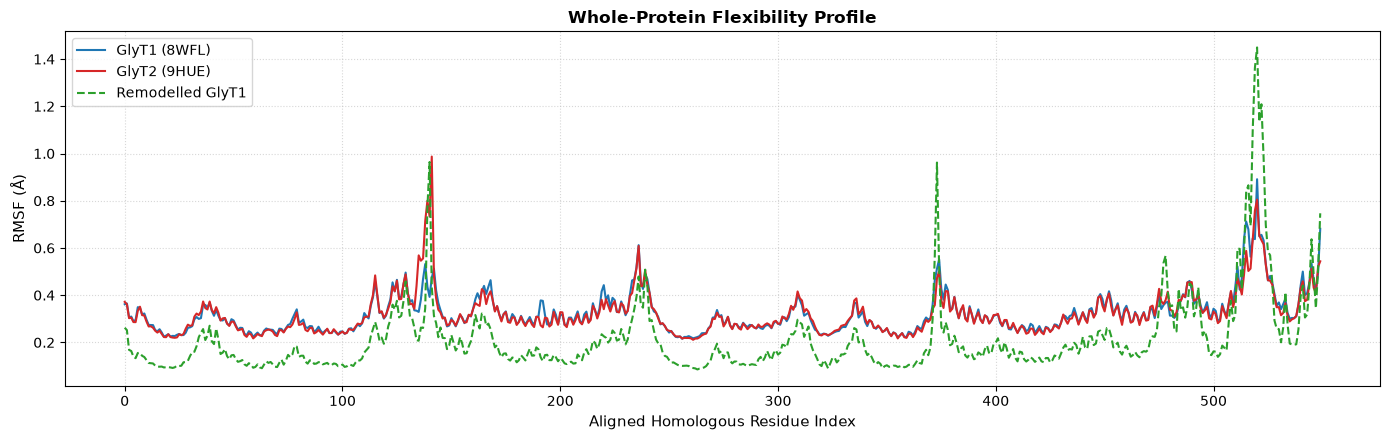

In [ ]:
res_indices = np.arange(len(rmsf_g1))

plt.figure(figsize=(14, 4.5))
plt.plot(
    res_indices, rmsf_g1, label="GlyT1 (8WFL)", color="#1f77b4", linewidth=1.5
)
plt.plot(
    res_indices, rmsf_g2, label="GlyT2 (9HUE)", color="#d62728", linewidth=1.5
)
plt.plot(
    res_indices,
    rmsf_mod,
    label="Remodelled GlyT1",
    color="#2ca02c",
    linestyle="--",
    linewidth=1.5,
)

plt.xlabel("Aligned Homologous Residue Index", fontsize=11)
plt.ylabel("RMSF (Å)", fontsize=11)
plt.title(
    "Whole-Protein Flexibility Profile",
    fontsize=12,
    fontweight="bold",
)
plt.legend(frameon=True, loc="upper left")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

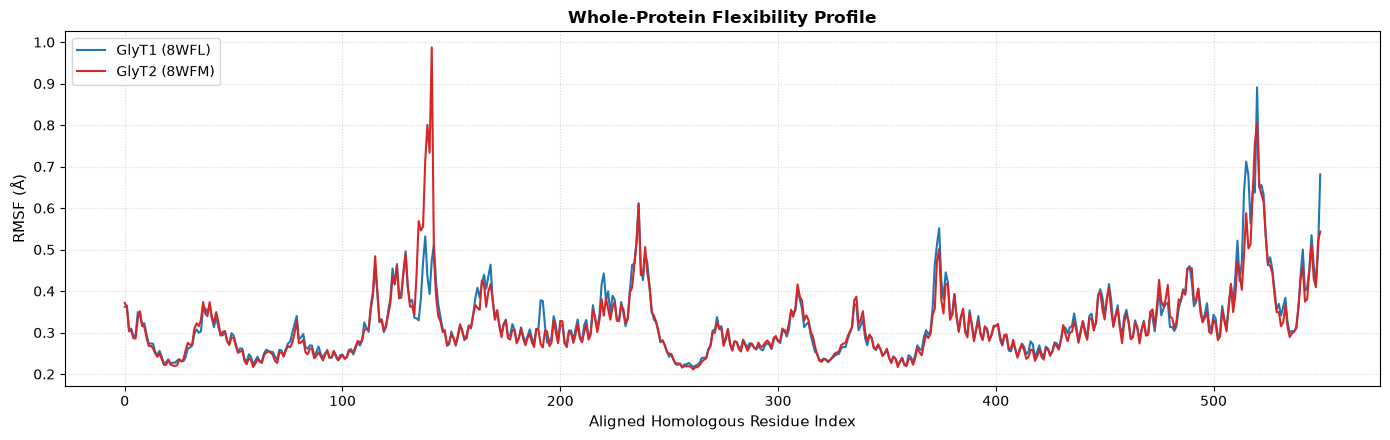

In [ ]:
res_indices = np.arange(len(rmsf_g1))

plt.figure(figsize=(14, 4.5))
plt.plot(
    res_indices, rmsf_g1, label="GlyT1 (8WFL)", color="#1f77b4", linewidth=1.5
)
plt.plot(
    res_indices, rmsf_g2, label="GlyT2 (8WFM)", color="#d62728", linewidth=1.5
)

plt.xlabel("Aligned Homologous Residue Index", fontsize=11)
plt.ylabel("RMSF (Å)", fontsize=11)
plt.title(
    "Whole-Protein Flexibility Profile",
    fontsize=12,
    fontweight="bold",
)
plt.legend(frameon=True, loc="upper left")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()